# TinyShakespeare
 ### It looks like we can learn patterns with RNNs. But how about if there is more structure and style in the data?

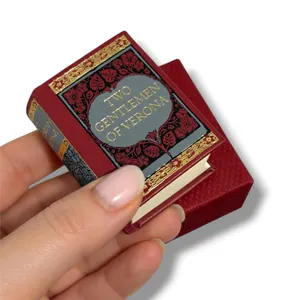

*First Citizen:*

> *Our business is not unknown to the senate; they have
had inkling this fortnight what we intend to do,
which now we'll show 'em in deeds. They say poor
suitors have strong breaths: they shall know we
have strong arms too.*

*MENENIUS:*
> *Why, masters, my good friends, mine honest neighbours,
Will you undo yourselves?*

In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import re
from collections import Counter
from torch import optim
import math

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [ ]:
!wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

lines = []

with open("input.txt", "r", encoding="utf-8") as f:

    for i, line in enumerate(f):
        lines.append(line)

text_pretraining = ''.join(lines)

In [ ]:
#splitting for evaluation
split = int(0.9 * len(text_pretraining))

train_text = text_pretraining[:split]
val_text = text_pretraining[split:]

In [ ]:
class ShakespeareDataset(Dataset):
    def __init__(self, text, method = "word", sequence_length = 50, stride=10):
        self.text = text
        self.method = method
        self.sequence_length = sequence_length
        self.stride = stride

        #tokenizing now based on the method:

        if method == "word":
            self.tokens = re.findall(r"\w+|[^\w\s]|\s+", self.text)
        elif method == "char":
            self.tokens = list(self.text)
        #exercise:
        #1. Try some other encoding methods like bpe
        #2. Complete this from start again

        #building the volabulary from the tokens:

        #1. Using a dictionary/counter and removing some outlier words/charecters

        tokens_counter = Counter(self.tokens)
        self.vocabulary_token_to_index = {}
        self.vocabulary_index_to_token = {}

        self.vocabulary_token_to_index = {"<UNK>": 0}
        self.vocabulary_index_to_token = {0: "<UNK>"}
        for token, count in tokens_counter.items():
            if count >=1:
                self.vocabulary_token_to_index[token] = len(self.vocabulary_token_to_index)
                self.vocabulary_index_to_token[len(self.vocabulary_token_to_index) - 1] = token


        self.Vocabulary_length = len(self.vocabulary_token_to_index)
        #after the vocabulary now we need to construct the dataset for next word predictor
        self.encoded_tokens = [
        self.vocabulary_token_to_index.get(
            token,
            self.vocabulary_token_to_index["<UNK>"]
        )
            for token in self.tokens
        ]

        #build the encoded sequences now

        self.encoded_sequences = []

        for i in range(0, len(self.encoded_tokens) - sequence_length, stride):
            encoded_sequence = self.encoded_tokens[i:i + sequence_length]

            if len(encoded_sequence) == sequence_length:
                self.encoded_sequences.append(encoded_sequence)


    def __len__(self):
        return len(self.encoded_sequences)

    def __getitem__(self, idx):
        sequence = self.encoded_sequences[idx]

        x = sequence[:-1]
        y = sequence[1:]

        return (torch.tensor(x, dtype=torch.long), torch.tensor(y, dtype=torch.long))

In [ ]:
class TokenRepresentation(nn.Module):
    def __init__(self, vocab_size, embedding_dim=32, threshold=100):
        super().__init__()

        self.vocab_size = vocab_size
        self.use_one_hot = vocab_size < threshold

        if self.use_one_hot:
            self.output_dim = vocab_size
        else:
            self.embedding = nn.Embedding(vocab_size, embedding_dim)
            self.output_dim = embedding_dim

    def forward(self, x):
        if self.use_one_hot:
            return F.one_hot(x, num_classes=self.vocab_size).float()
        else:
            return self.embedding(x)

In [ ]:
dataset = ShakespeareDataset(
    train_text,
    method="char",
    sequence_length=50,
    stride=10
)

val_dataset = ShakespeareDataset(
    val_text,
    method="char",
    sequence_length=50,
    stride=50
)

print("Vocabulary size:", dataset.Vocabulary_length)
print("Number of sequences:", len(dataset))

dataloader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)
val_dataloader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

In [ ]:

val_i2t = val_dataset.vocabulary_index_to_token

train_t2i = dataset.vocabulary_token_to_index

new_val_sequences = []

for seq in val_dataset.encoded_sequences:
    tokens = [
        val_i2t[idx]
        for idx in seq
    ]

    train_indices = [
        train_t2i.get(token, train_t2i["<UNK>"])
        for token in tokens
    ]

    new_val_sequences.append(train_indices)
val_dataset.encoded_sequences = new_val_sequences

In [ ]:
dataset = ShakespeareDataset(
    text_pretraining,
    method="char",
    #method = "word",
    sequence_length=100,
    stride=10
)

print("Vocabulary size:", dataset.Vocabulary_length)
print("Number of sequences:", len(dataset))

dataloader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

In [ ]:
representation = TokenRepresentation(
    vocab_size=dataset.Vocabulary_length,
    embedding_dim=32
)
print(dataset.Vocabulary_length)


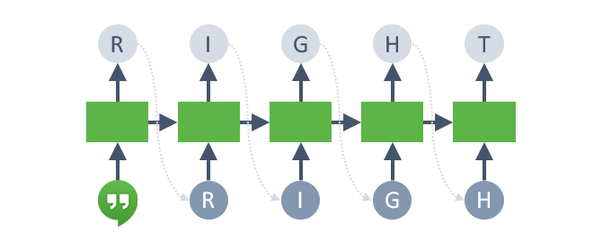

In [ ]:
class CharRNN(nn.Module):
    def __init__(self, input_size, vocab_size, hidden_size):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, h=None):

        out, h = self.rnn(x, h)

        out = self.fc(out)

        return out, h

class CharLSTM(nn.Module):

    def __init__(self, input_size, vocab_size, hidden_size):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_size,
            vocab_size
        )

    def forward(self, x, states=None):
        out, states = self.lstm(x, states)
        out = self.fc(out)
        return out, states


In [ ]:
def train_model(
    model,
    dataloader,
    dataset,
    representation,
    method,
    num_epochs=10,
    learning_rate=1e-3,
    embedding_dim = 32,
    device=None
):

    model = model.to(device)
    representation = representation.to(device)

    criterion = nn.CrossEntropyLoss()

    if method == "word":
        input_size = embedding_dim
        optimizer = optim.Adam(list(model.parameters()) + list(representation.parameters()), lr=learning_rate)

    else:
        input_size = dataset.Vocabulary_length
        optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    for epoch in range(num_epochs):
        total_loss = 0.0

        for x_batch, y_batch in dataloader:

            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            X = representation(x_batch)

            logits, _ = model(X)

            loss = criterion(
                logits.reshape(-1, dataset.Vocabulary_length),
                y_batch.reshape(-1)
            )

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(dataloader)

        if epoch % 2 == 0:
            print(
                f"Epoch {epoch + 1}/{num_epochs}, "
                f"Loss = {avg_loss:.4f}"
            )

    return model, representation, loss

In [ ]:
 # Generate text
@torch.no_grad()
def generate(model, start, representation, dataset, length=100, device = None):
    model = model.to(device)
    representation = representation.to(device)

    model.eval()

    char_to_idx = dataset.vocabulary_token_to_index
    idx_to_char = dataset.vocabulary_index_to_token

    # Split start input based on method
    if dataset.method == "word":
        start_tokens = re.findall(r"\w+|[^\w\s]|\s+", start)
    else:  # "char"
        start_tokens = list(start)

    input_ids = [
        char_to_idx.get(token, char_to_idx["<UNK>"]) for token in start_tokens
    ]
    input_tensor = torch.tensor([input_ids], dtype=torch.long).to(device)

    result = start_tokens
    hidden = None
    with torch.no_grad():
        for _ in range(length):
            x_rep = representation(input_tensor)

            logits, hidden = model(x_rep, hidden)

            # prediction for last character

            logits = logits[:, -1, :]
            temperature = 0.8
            probs = torch.softmax(logits / temperature, dim=-1)
            next_idx = torch.multinomial(probs, 1).item()

            next_token = idx_to_char.get(next_idx)


            result.append(next_token)

            # Feed back the single predicted token
            input_tensor = torch.tensor([[next_idx]], dtype=torch.long).to(device)

    return "".join(result) if dataset.method == "char" else "".join(result)


In [ ]:
input_size = dataset.Vocabulary_length
if dataset.method == "word":
    input_size = 32


model_RNN = CharRNN(
    input_size=input_size,
    vocab_size=dataset.Vocabulary_length,
    hidden_size=128
)

model_RNN, representation_rnn, _ = train_model(model_RNN, dataloader, dataset, representation, dataset.method, device = device)

In [ ]:
print(generate(model_RNN, "Firest Citizen", representation_rnn, dataset, 100, device = device))

In [ ]:
total_params = sum(p.numel() for p in model_RNN.parameters())
print(f"Total Parameters: {total_params:,}")

In [ ]:
input_size = dataset.Vocabulary_length
if dataset.method == "word":
    input_size = 32
model_LSTM = CharLSTM(
    input_size = input_size,
    vocab_size=dataset.Vocabulary_length,
    hidden_size=128
)

model_LSTM, representation_LSTM, _ = train_model(model_LSTM, dataloader, dataset, representation, dataset.method, device=device)

In [ ]:
print(generate(model_LSTM, "First Citizen:\n", representation_LSTM, dataset, length=100, device = device))

In [ ]:
total_params = sum(p.numel() for p in model_LSTM.parameters())
print(f"Total Parameters: {total_params:,}")

In [ ]:
def evaluate_perplexity(
    model,
    dataloader,
    dataset,
    representation,
    device
):
    model = model.to(device)
    representation = representation.to(device)

    model.eval()
    representation.eval()

    criterion = nn.CrossEntropyLoss(reduction="sum")

    total_loss = 0.0
    total_tokens = 0

    with torch.no_grad():
        for x_batch, y_batch in dataloader:

            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
            X = representation(x_batch)
            logits, _ = model(X)
            loss = criterion(
                logits.reshape(-1, dataset.Vocabulary_length),
                y_batch.reshape(-1)
            )

            total_loss += loss.item()
            total_tokens += y_batch.numel()
    avg_loss = total_loss / total_tokens
    perplexity = math.exp(avg_loss)

    return avg_loss, perplexity

In [ ]:
rnn_val_loss, rnn_perplexity = evaluate_perplexity(
    model_RNN,
    val_dataloader,
    dataset,
    representation_rnn,
    device
)

print(f"RNN Validation Loss: {rnn_val_loss:.4f}")
print(f"RNN Validation Perplexity: {rnn_perplexity:.4f}")

In [ ]:
lstm_val_loss, lstm_perplexity = evaluate_perplexity(
    model_LSTM,
    val_dataloader,
    dataset,
    representation_LSTM,
    device
)

print(f"LSTM Validation Loss: {lstm_val_loss:.4f}")
print(f"LSTM Validation Perplexity: {lstm_perplexity:.4f}")